# Quema y aumento neto del área agropecuaria

Este notebook estima si un municipio registra un mayor aumento neto del área agropecuaria cuando se quema una mayor proporción de su vegetación natural no forestal. Primero usa las observaciones municipales y después examina los desfases en la serie agregada regional.

Se ajusta la misma especificación municipal en dos escalas definidas en el notebook 01. El resultado principal es el cambio neto en pp del territorio de $t-1$ (`d_agro_pct`). El complementario es el crecimiento en % del área agropecuaria de $t-1$ (`crec_agro_pct`). En ambos casos el numerador es el cambio neto en hectáreas. Como el cociente entre los dos denominadores varía por municipio y año, la segunda regresión vuelve a estimar los coeficientes.

## 1. Preparar el entorno

Se cargan las funciones de lectura, las herramientas de visualización y las rutas de las salidas del análisis municipal.

In [1]:
import sys
from importlib import import_module
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

raiz = Path.cwd().resolve()
if not (raiz / "scripts" / "config.py").is_file():
    raiz = raiz.parent
if not (raiz / "scripts" / "config.py").is_file():
    raise FileNotFoundError("Abre el notebook desde la raíz del proyecto o notebooks/.")
sys.path.insert(0, str(raiz / "scripts"))

import config as cfg
from utils import estilo_matplotlib, leer_csv

derivados = cfg.DERIVADOS / "municipal"
tablas = cfg.TABLAS / "municipal"
figuras = cfg.FIGURAS / "municipal"
for carpeta in (derivados, tablas, figuras):
    carpeta.mkdir(parents=True, exist_ok=True)
estilo_matplotlib()

## 2. Cargar el panel y la serie regional

Ejecuta el notebook 01 actualizado para regenerar el panel y la serie con los dos denominadores de $t-1$. El panel es la entrada del modelo con efectos fijos. La serie regional se usa al final para comparar la quema y el cambio agropecuario en años consecutivos.

In [2]:
panel = leer_csv(derivados / "panel_municipio_anio.csv")
regional = leer_csv(derivados / "serie_altillanura_anual.csv")

## 3. Ajustar el modelo y las pruebas de sensibilidad

Se ajusta una regresión lineal por mínimos cuadrados. Para un municipio $i$ en el año $t$, el modelo incluye la tasa de quema de formación natural no forestal en $t$ y en $t-1$, y la lluvia CHIRPS de diciembre de $t-1$ a marzo de $t$. La quema es anual. En un contraste se usan focos FIRMS Terra de diciembre a marzo por 100 km², para $t$ y $t-1$, en la misma muestra que el ajuste comparable de MapBiomas.

Los **efectos fijos municipales** descuentan la media de cada variable dentro del municipio, de modo que los coeficientes se estiman a partir de sus variaciones en el tiempo. En la sensibilidad con efectos fijos de año también se absorben los cambios comunes a los municipios en cada año. Se usa un coeficiente común para los siete municipios por predictor.

Cada coeficiente de MapBiomas se interpreta por **1 pp adicional de cobertura quemada**, manteniendo fijos los otros predictores. En la escala principal mide el cambio en pp del territorio. En la complementaria mide el cambio en pp de la tasa de crecimiento agropecuario. El rezago vincula la quema de $t-1$ con el cambio de $t-1$ a $t$. La coincidencia contemporánea no establece el orden dentro del año.

### Intervalos por bootstrap de bloques móviles

1. Se ajusta el modelo original con las filas completas de cada especificación. El principal tiene 168 filas, siete municipios en 24 años.
2. Se forman ventanas móviles de tres años calendario. Para 2001–2024 hay 22 ventanas, desde 2001–2003 hasta 2022–2024. Cada año aporta juntas todas sus filas disponibles.
3. Se sortean ventanas **con reemplazo**. Para 24 años se extraen ocho ventanas y se concatenan para formar 24 posiciones de calendario. Si la longitud del calendario no es múltiplo de tres, se recorta el final. Los años pueden repetirse y los huecos de las muestras filtradas aportan cero filas. Cada fila conserva su rezago original. Si sale el bloque 2009–2011, el dato rezagado de 2009 sigue siendo el de 2008.
4. Se reajusta la regresión, incluidos sus efectos fijos, en cada una de 2.000 réplicas. Se descartan las réplicas en las que el modelo no identifica todos los coeficientes.
5. Para cada coeficiente se toman los percentiles **2,5 y 97,5** de las réplicas válidas. La tabla muestra el ajuste de la muestra original, los límites del intervalo y los recuentos de observaciones, municipios, años y réplicas.

Los bloques conservan choques comunes a los municipios de un año y parte de la dependencia entre años cercanos. La continuidad se corta al unir bloques sorteados. El intervalo es aproximado y depende de la longitud del bloque y del período observado.

In [3]:
modelos = import_module("03_panel_efectos_fijos")
muestra_comun = panel.dropna(subset=["focos_seca_dens", "focos_seca_dens_rez1",
                                    "tasa_quema_natural", "tasa_quema_natural_rez1"])
especificaciones = [
    ("Principal", panel, {}),
    ("Efectos fijos de año", panel, {"efectos_anio": True}),
    ("Sin años con limitaciones de Landsat", panel, {"excluir_anios_limitados": True}),
    ("Sin Puerto Carreño 2014", panel, {"excluir_salto_carreno": True}),
    ("Agropecuario sin plantaciones forestales", panel, {"resultado": "d_agro_sin_forestal_pct"}),
    ("Quema en muestra común con FIRMS", muestra_comun, {}),
    ("FIRMS en muestra común", muestra_comun, {"exposicion": "focos_seca_dens"}),
]
# La exclusión de plantaciones cambia la definición del resultado principal.
# Las demás especificaciones se comparan en ambas escalas.
escalas = [
    ("Territorio previo (pp)", "d_agro_pct", especificaciones),
    ("Agro previo (%)", "crec_agro_pct",
     [esp for esp in especificaciones if "resultado" not in esp[2]]),
]
resultados = pd.concat(
    [modelos.ajustar(datos, **{"resultado": resultado, **opciones})
     .assign(modelo=nombre, escala=escala)
     for escala, resultado, variantes in escalas
     for nombre, datos, opciones in variantes],
    ignore_index=True,
)
resultados.to_csv(tablas / "asociacion_municipal.csv", index=False, encoding="utf-8-sig")
columnas = ["escala", "variable", "coef", "ic95_inf", "ic95_sup", "n", "replicas_validas"]
display(resultados.loc[resultados["modelo"].eq("Principal"), columnas].round(5))
display(resultados.loc[~resultados["modelo"].eq("Principal")].round(5))

,escala,variable,coef,ic95_inf,ic95_sup,n,replicas_validas
0,Territorio previo (pp),tasa_quema_natural,-0.01425,-0.02451,0.00190,168,2000
1,Territorio previo (pp),tasa_quema_natural_rez1,0.00567,-0.00802,0.01365,168,2000
2,Territorio previo (pp),lluvia_seca_mm,-0.00028,-0.00085,0.00124,168,2000
21,Agro previo (%),tasa_quema_natural,-0.14203,-0.25953,0.05397,168,2000
22,Agro previo (%),tasa_quema_natural_rez1,-0.04757,-0.16533,0.06332,168,2000
23,Agro previo (%),lluvia_seca_mm,-0.00326,-0.01068,0.00822,168,2000


,variable,coef,ic95_inf,ic95_sup,n,municipios,anios,bloque,replicas_validas,replicas_solicitadas,modelo,escala
3,tasa_quema_natural,-0.02197,-0.04760,-0.00289,168,7,24,3,2000,2000,Efectos fijos de año,Territorio previo (pp)
4,tasa_quema_natural_rez1,0.01178,-0.00860,0.03899,168,7,24,3,2000,2000,Efectos fijos de año,Territorio previo (pp)
5,lluvia_seca_mm,-0.00008,-0.00155,0.00294,168,7,24,3,2000,2000,Efectos fijos de año,Territorio previo (pp)
6,tasa_quema_natural,-0.01856,-0.03109,0.00098,126,7,18,3,2000,2000,Sin años con limitaciones de Landsat,Territorio previo (pp)
7,tasa_quema_natural_rez1,0.00673,-0.00944,0.01628,126,7,18,3,2000,2000,Sin años con limitaciones de Landsat,Territorio previo (pp)
8,lluvia_seca_mm,-0.00025,-0.00116,0.00142,126,7,18,3,2000,2000,Sin años con limitaciones de Landsat,Territorio previo (pp)
9,tasa_quema_natural,-0.01582,-0.02809,-0.00023,167,7,24,3,2000,2000,Sin Puerto Carreño 2014,Territorio previo (pp)
10,tasa_quema_natural_rez1,0.00683,-0.00554,0.01420,167,7,24,3,2000,2000,Sin Puerto Carreño 2014,Territorio previo (pp)
11,lluvia_seca_mm,-0.00029,-0.00092,0.00119,167,7,24,3,2000,2000,Sin Puerto Carreño 2014,Territorio previo (pp)
12,tasa_quema_natural,-0.01429,-0.02662,0.00431,168,7,24,3,2000,2000,Agropecuario sin plantaciones forestales,Territorio previo (pp)


### Lectura del ajuste principal

En la escala principal, por cada punto porcentual adicional de cobertura natural quemada, la estimación es **−0,014 pp** de cambio agropecuario en el mismo año (IC del 95 % de **−0,025 a +0,002**) y **+0,006 pp** al año siguiente (**−0,008 a +0,014**). Ambos intervalos incluyen cero. La estimación rezagada es positiva, pero el intervalo es compatible con asociaciones pequeñas en ambas direcciones.

En la escala complementaria, las estimaciones son **−0,142 pp** del crecimiento agropecuario en el mismo año (IC del 95 % de **−0,260 a +0,054**) y **−0,048 pp** al año siguiente (**−0,165 a +0,063**). El coeficiente rezagado cambia de signo entre escalas y ambos intervalos incluyen cero. Las sensibilidades se presentan en las dos escalas, con la exclusión de plantaciones aplicada al indicador principal.

### Qué cambia en las pruebas de sensibilidad del indicador principal

- **Efectos fijos de año.** Absorben variaciones compartidas por los municipios en un año. La asociación contemporánea se hace más negativa y su intervalo queda por debajo de cero. El intervalo del rezago sigue incluyendo cero.
- **Años con limitaciones de Landsat.** Se excluyen 2002, 2005 y 2007 y también 2003, 2006 y 2008, porque estos últimos usan el fuego de un año señalado como rezago. La muestra baja de 168 a 126 observaciones. Ambos intervalos incluyen cero.
- **Puerto Carreño en 2014.** Se retira una sola observación, asociada con un salto de cobertura de interpretación incierta. El intervalo contemporáneo queda apenas por debajo de cero y el del rezago incluye cero.
- **Sin plantaciones forestales.** Se redefine el cambio agropecuario. Las estimaciones quedan cerca del ajuste principal.
- **Contraste con FIRMS.** La comparación usa las mismas 161 observaciones para las dos fuentes. El coeficiente contemporáneo de FIRMS es negativo y su intervalo queda por debajo de cero. El rezago incluye cero. FIRMS mide focos de diciembre a marzo por 100 km² y MapBiomas mide proporción de cobertura quemada en el año calendario. Los coeficientes tienen unidades distintas.

## 4. Comparar los coeficientes de MapBiomas en la escala principal

Cada punto es una estimación y cada segmento horizontal es su intervalo aproximado del 95 %. La línea vertical marca cero. La gráfica omite el contraste FIRMS porque usa otra unidad.

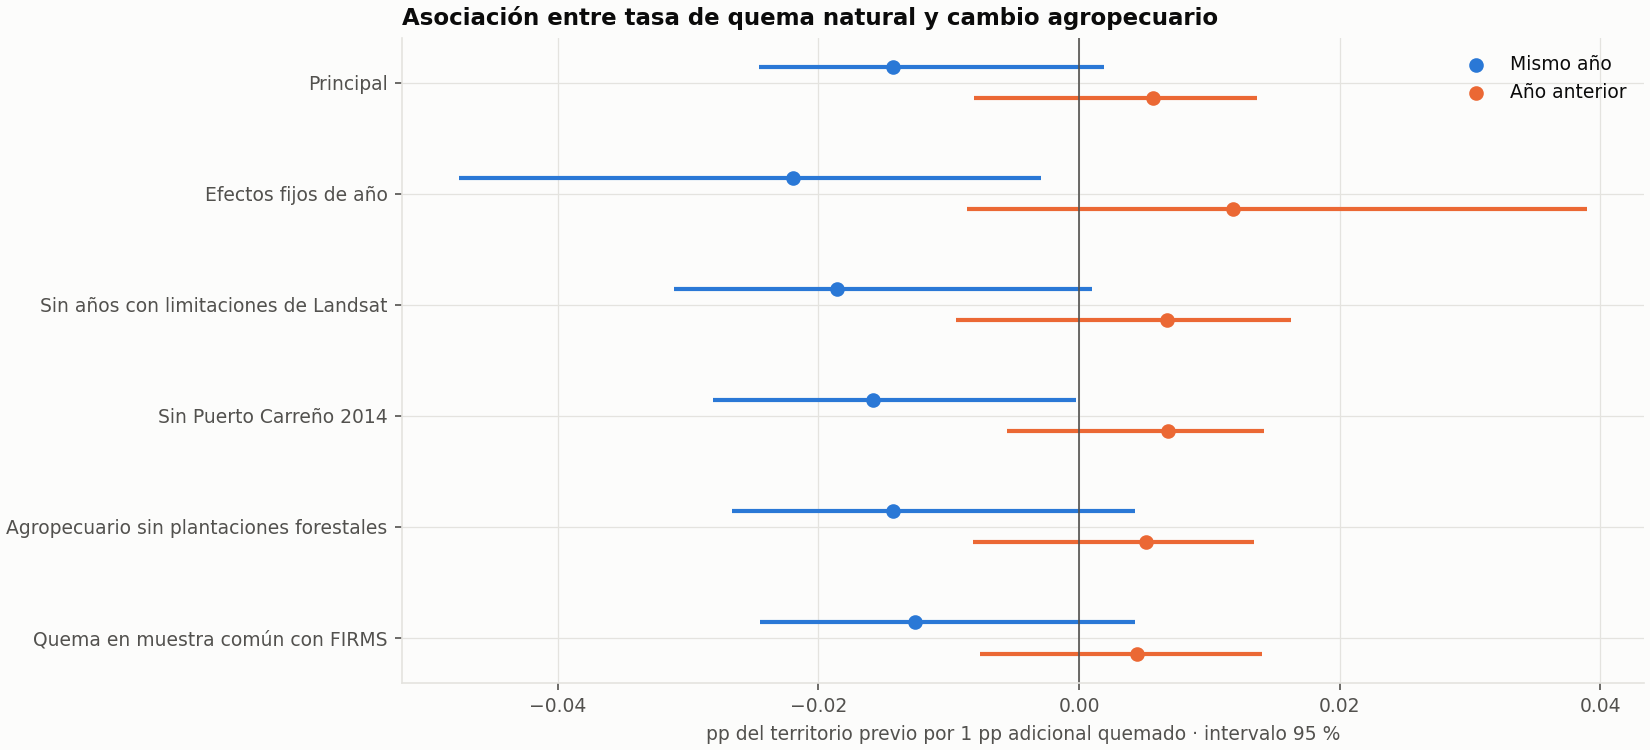

In [4]:
quema = resultados[resultados["variable"].str.startswith("tasa_quema_natural")
                   & resultados["escala"].eq("Territorio previo (pp)")]
orden = quema["modelo"].unique()
fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")
for variable, etiqueta, color, desplazamiento in [
    ("tasa_quema_natural", "Mismo año", cfg.COLOR_AGRO, -0.14),
    ("tasa_quema_natural_rez1", "Año anterior", cfg.COLOR_SABANA, 0.14),
]:
    d = quema[quema["variable"].eq(variable)].set_index("modelo").loc[orden]
    posiciones = [i + desplazamiento for i in range(len(orden))]
    ax.hlines(posiciones, d["ic95_inf"], d["ic95_sup"], color=color)
    ax.scatter(d["coef"], posiciones, color=color, label=etiqueta)
ax.set(yticks=range(len(orden)), yticklabels=orden,
       title="Asociación entre tasa de quema natural y cambio agropecuario",
       xlabel="pp del territorio previo por 1 pp adicional quemado · intervalo 95 %")
ax.invert_yaxis()
ax.axvline(0, color=cfg.COLOR_TEXTO_2, linewidth=0.8)
ax.legend()
fig.savefig(figuras / "03_coeficientes_municipales.png")
plt.show()

### Lectura de la figura

Los puntos del mismo año quedan a la izquierda de cero en todas las variantes graficadas de MapBiomas, pero sus intervalos no siempre excluyen cero. Los intervalos del año anterior cruzan cero en todas las variantes graficadas. Una asociación contemporánea tampoco permite saber si la quema ocurrió antes o después del cambio de cobertura dentro del año.

## 5. Explorar los desfases en la serie regional

Se agrega el territorio de los siete municipios en **24 observaciones anuales** y se calcula la correlación entre la tasa de quema natural no forestal y el cambio neto agropecuario. Esta exploración usa dos series regionales. Los efectos municipales y la lluvia pertenecen al modelo de panel de la sección anterior.

Tomando como ejemplo la quema de 2010, el desfase **−1** la compara con el cambio de 2009, **0** con el de 2010 y **+1** con el de 2011. El desfase **+1** es el que corresponde a la pregunta sobre quema seguida de cambio agropecuario.

El cálculo se hace para ambas escalas agropecuarias. Para cada escala, la comparación se repite con las series originales y tras restar la tendencia lineal de cada una. En el segundo caso, la correlación compara las desviaciones de cada serie respecto a su tendencia. El **preblanqueo** busca descontar la inercia de la serie de quema y aplica el mismo filtro a la serie agropecuaria. Aquí se seleccionó `p_ar = 0` en ambos tratamientos de la serie de quema, por lo que el filtro se limitó a centrar cada serie.

En la tabla, `r` es la correlación, `n_pares` indica cuántos años pudieron emparejarse y `banda95` es el umbral aproximado para comparar con el valor absoluto de `r`. La banda es puntual para cada desfase y se usa como referencia exploratoria.

In [5]:
ccf = import_module("05_correlacion_regional")
correlaciones = pd.concat(
    [ccf.correlacion_cruzada(regional, "tasa_quema_natural", resultado=resultado)
     .assign(escala=escala)
     for escala, resultado, _ in escalas],
    ignore_index=True,
)
correlaciones.to_csv(tablas / "correlacion_cruzada_regional.csv", index=False)
display(correlaciones.round(3))

,tratamiento,variable,p_ar,rezago,r,n_pares,banda95,significativo,escala
0,sin quitar tendencia,tasa_quema_natural,0,-1,-0.137,23,0.409,False,Territorio previo (pp)
1,sin quitar tendencia,tasa_quema_natural,0,0,-0.054,24,0.400,False,Territorio previo (pp)
2,sin quitar tendencia,tasa_quema_natural,0,1,0.212,23,0.409,False,Territorio previo (pp)
3,tendencia lineal removida,tasa_quema_natural,0,-1,-0.362,23,0.409,False,Territorio previo (pp)
4,tendencia lineal removida,tasa_quema_natural,0,0,-0.203,24,0.400,False,Territorio previo (pp)
5,tendencia lineal removida,tasa_quema_natural,0,1,0.115,23,0.409,False,Territorio previo (pp)
6,sin quitar tendencia,tasa_quema_natural,0,-1,-0.322,23,0.409,False,Agro previo (%)
7,sin quitar tendencia,tasa_quema_natural,0,0,-0.182,24,0.400,False,Agro previo (%)
8,sin quitar tendencia,tasa_quema_natural,0,1,0.153,23,0.409,False,Agro previo (%)
9,tendencia lineal removida,tasa_quema_natural,0,-1,-0.426,23,0.409,True,Agro previo (%)


### Lectura de la tabla regional

En la escala principal, para **+1**, la correlación es **+0,21** con las series originales y **+0,11** al retirar la tendencia. En ambos casos hay **23 pares de años** y la banda aproximada es **±0,41**. Ninguno de los seis valores supera su banda, de ahí `significativo = False` en todas las filas. La correlación de mayor magnitud es **−0,36** al quitar la tendencia en el desfase **−1**. Ese desfase sitúa el cambio agropecuario antes de la quema.

En la escala complementaria, las correlaciones para **+1** son **+0,15** y **+0,11** al retirar la tendencia. Ambas quedan dentro de la banda de **±0,41**. La correlación sin tendencia en **−1** es **−0,43** y supera en magnitud su banda puntual. Ese desfase ubica el cambio agropecuario antes de la quema y la banda se usa como referencia exploratoria.

## Balance del análisis

El panel municipal y la exploración regional ofrecen poca evidencia de que una mayor quema natural no forestal vaya seguida de un mayor aumento agropecuario al año siguiente. La asociación del mismo año es negativa en el panel, con incertidumbre que varía entre especificaciones. Para saber si se quemaron las mismas hectáreas que luego cambiaron de cobertura se necesitarían datos espaciales de ambos procesos.

La guía del proyecto documenta un ARIMA univariado para pronosticar el nivel de superficie agropecuaria en 1985–2024. Este notebook estudia asociaciones en 2001–2024. El [notebook 04](04_prediccion_regional.ipynb) compara un ARIMA de referencia con modelos que incorporan lluvia y quema en los mismos años de evaluación. Allí queda pendiente verificar la disponibilidad histórica de los datos al momento del pronóstico.